# CODEX human healthy intestine

In this tutorial we will perform a simple analysis of a published dataset from the study "Organization of the human intestine at single-cell resolution" https://doi.org/10.1038/s41586-023-05915-x
The dataset along with all additional information can be downloaded here: https://datadryad.org/dataset/doi:10.5061/dryad.pk0p2ngrf
It is already segmented, normalized and annotated, so we can directly start with spatial analysis. 

In [ ]:
# Import SPACEc first
import spacec as sp

# Import other libraries that will be used
import pandas as pd
import time
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns


Read in the downloaded csv file.

In [ ]:
# Import the data from the downloaded csv file.
df = pd.read_csv("/doi_10_5061_dryad_pk0p2ngrf__v20230913/dataset/23_09_CODEX_HuBMAP_alldata_Dryad_merged.csv")
df

Convert the dataframe to an anndata object and remove unwanted columns.

In [ ]:
# get the column index for the last marker 
col_num_last_marker = df.columns.get_loc('CD161')
print(col_num_last_marker)

In [ ]:
# inspect which markers work, and drop the ones that did not work from the clustering step
# make an anndata to be compatible with the downstream clustering step
adata = sp.hf.make_anndata(
    df_nn = df,
    marker_list = list(df.columns[:col_num_last_marker + 1]), # this is the column index that has the last protein feature # the rest will go into obs
    nonFuncAb_list = ['Unnamed: 0'] # Remove the antibodies that are not working from the clustering step
)

# save the anndata object (optional)
# adata.write_h5ad("your_path/data/23_09_CODEX_HuBMAP_alldata_Dryad_merged.h5ad")

## Inspecting the dataset

In [ ]:
# Print basic information about the AnnData object.
print("Number of cells:", adata.n_obs)
print("Number of markers:", len(adata.var_names))
print("Number of unique regions:", adata.obs["unique_region"].nunique())
print("Number of unique tissue donors:", adata.obs["donor"].nunique())
print("Number of unique cell types:", adata.obs["Cell Type"].nunique())

In [ ]:
adata.obs.Tissue_location.unique()

For the purpose of this tutorial we will focus on the differences between the duodenum and the descending sigmoid colon.

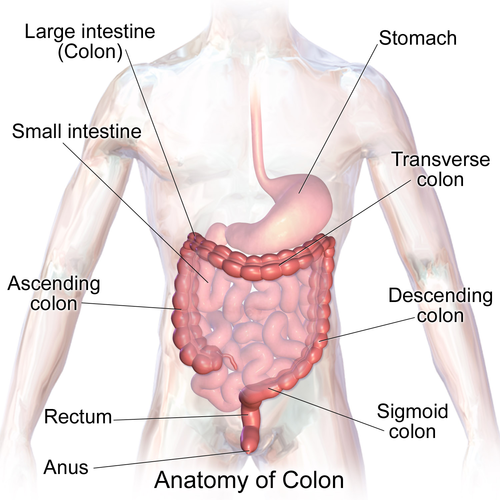

https://upload.wikimedia.org/wikipedia/commons/6/62/Blausen_0603_LargeIntestine_Anatomy.png

In [ ]:
# subset the data to only include 'Duodenum' and 'Descending - Sigmoid'
adata = adata[adata.obs['Tissue_location'].isin(['Duodenum', 'Ascending'])].copy()
print("Number of cells after subsetting:", adata.n_obs)
# Print the number of cells in each tissue location
print(adata.obs['Tissue_location'].value_counts())

## Reproducing the cell type annotation

The provided dataset is already annotated. This gives us the opportunity to inspect how well the clustering is capturing the annotated cell types.

In [ ]:
# Set the random seed for reproducibility
clustering_random_seed = 0

To run the dataset fast on CPU based machines we recommend flowSOM. If you prefer Leiden clustering and have a large dataset with more than 200000 cells we recommend using the leiden_gpu implementation as it is much faster. Please notice that the leiden GPU implementation depends on Nvidia RAPIDS and is therefore only available on Linux or on Windows through WSL.

In [ ]:
# Use this cell-type specific markers for cell type annotation
marker_list = ['MUC2', 'SOX9', 'MUC1', 'CD31', 'Synapto', 'CD49f', 'CD15', 'CHGA',
       'CDX2', 'ITLN1', 'CD4', 'CD127', 'Vimentin', 'HLADR', 'CD8', 'CD11c',
       'CD44', 'CD16', 'BCL2', 'CD3', 'CD123', 'CD38', 'CD90', 'aSMA', 'CD21',
       'NKG2D', 'CD66', 'CD57', 'CD206', 'CD68', 'CD34', 'aDef5', 'CD7',
       'CD36', 'CD138', 'CD45RO', 'Cytokeratin', 'CD117', 'CD19', 'Podoplanin',
       'CD45', 'CD56', 'CD69', 'Ki67', 'CD49a', 'CD163', 'CD161']

# Start to measure time
start_time = time.time()

# clustering
adata = sp.tl.clustering(
    adata, 
    clustering='flowSOM', # can choose between leiden and louvian
    fs_xdim=10,    # Width dimension of the self-organizing map (SOM) grid
    fs_ydim=10,    # Height dimension of the SOM grid - together with fs_xdim creates a 10x10 node grid
    fs_rlen=10,    # Number of training iterations for the SOM algorithm - higher values may produce more stable clusters but increase computation time
    reclustering = False, # if true, no computing the neighbors and UMAP
    marker_list = marker_list, #if it is None, all variable names are used for clustering
    seed=clustering_random_seed, # random seed for clustering - reproducibility
    key_added='flowSOM', # key to add the clustering results to adata.obs
)

# End to measure time
end_time = time.time()
print("Execution time: {:.4f} seconds".format(end_time - start_time))

In [ ]:
sc.pl.dotplot(adata, 
              marker_list, # The list of markers to show on the x-axis
              'flowSOM', # The cluster column
              dendrogram = True) # Show the dendrogram

Since we already have cell types annotations in the example dataset we can compare how well our clusters capture different cell types. For a tutorial on how to manually annotate the clusters based on marker expression, have a look at notebook 04_clustering.

In [ ]:
# Create the contingency table from adata.obs columns.
ct = pd.crosstab(adata.obs['flowSOM'], adata.obs['Cell Type'])

# Calculate the percentage of each cell type within each cluster.
percentages = ct.div(ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(9, 20))
sns.heatmap(percentages, annot=False, cmap="coolwarm")
plt.title("Enrichemnt of Cell Types in Clusters")
plt.xlabel("Cell Type")
plt.ylabel("Cluster")
plt.show()

Since we performed overclustering (more clusters than cell types), we can merge multiple clusters if they show the same profile. However, we also see clusters that seem to contain multiple cell types. To resolve these mixed clusters, we can perform either an entire re-clustering with higher resolution or we sub-cluster a specific cluster (splitting the cluster in a new set of clusters).

In [ ]:
# Start to measure time
start_time = time.time()

# subclustering cluster 0, 3, 4 sequentially (could be optional for your own data)
sc.tl.leiden(adata, 
             seed=clustering_random_seed, # random seed for clustering - reproducibility
             restrict_to=('flowSOM',['98']), # select the cluster column name (your previously generated key) and the cluster name you want to subcluster
             resolution=0.5, # resolution for subclustering
             key_added='flowSOM_sub') # key added to adata.obs (keep it the same to avoid confusion and limit the adata object size)

# End to measure time
end_time = time.time()
print("Execution time: {:.4f} seconds".format(end_time - start_time))

Now we can better separate the mixed cluster:

In [ ]:
# Create the contingency table from adata.obs columns.
ct = pd.crosstab(adata.obs['flowSOM_sub'], adata.obs['Cell Type'])

# Calculate the percentage of each cell type within each cluster.
percentages = ct.div(ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(9, 20))
sns.heatmap(percentages, annot=False, cmap="coolwarm")
plt.title("Enrichemnt of Cell Types in Clusters")
plt.xlabel("Cell Type")
plt.ylabel("Cluster")
plt.show()

## Getting insights into cell type distribution

The stacked bar plot function provides a quick overview of the cell percentages per group. The underlying object is exported as well to perform statistics in python or another software of choice. 

In [ ]:
# cell type percentage table and visualization
ct_perc_tab, _ = sp.pl.stacked_bar_plot(
    adata = adata, # adata object to use 
    color = 'Cell Type', # column containing the categories that are used to fill the bar plot
    grouping = 'Tissue_location', # column containing a grouping variable (usually a condition or cell group) 
    cell_list = adata.obs['Cell Type'].unique(),  # list of cell types to plot, you can also see the entire cell types adata.obs['celltype_fine'].unique()
    palette=None, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # change it to true if you want to save the figure
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir = "output_dir", #output directory for the figure
    norm = False, # if True, then whatever plotted will be scaled to sum of 1
    fig_sizing= (12,6)
)

# show percentages
ct_perc_tab

In [ ]:
# Loop through each unique tissue region and create a plot
unique_locations = adata.obs['Tissue_location'].unique()

for loc in unique_locations:
    print(f"Plotting for region: {loc}")
    sp.pl.stacked_bar_plot(
        adata=adata[adata.obs['Tissue_location'] == loc],  # subset data for the region
        color='Cell Type',  # column containing the categories that are used to fill the bar plot
        grouping='unique_region',  # column containing a grouping variable
        cell_list=adata.obs['Cell Type'].unique(),  # list of cell types to plot
        palette=None,  # default is None which means the color comes from the anndata.uns
        savefig=False,  # change it to true if you want to save the figure
        output_fname=f"{loc}_stacked_bar_plot.png",  # file name for saving the figure
        output_dir="output_dir",  # output directory for the figure
        norm=False,  # if True, then whatever plotted will be scaled to sum of 1
        fig_sizing=(12, 6)
    )

In [ ]:
# cell type percentage table and visualization
ct_perc_tab, _ = sp.pl.stacked_bar_plot(
    adata = adata, # adata object to use 
    color = 'Cell Type', # column containing the categories that are used to fill the bar plot
    grouping = 'Major Community', # column containing a grouping variable (usually a condition or cell group) 
    cell_list = adata.obs['Cell Type'].unique(),  # list of cell types to plot, you can also see the entire cell types adata.obs['celltype_fine'].unique()
    palette=None, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # change it to true if you want to save the figure
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir = "output_dir", #output directory for the figure
    norm = False, # if True, then whatever plotted will be scaled to sum of 1
    fig_sizing= (12,6)
)

# show percentages
ct_perc_tab

In [ ]:
sp.pl.catplot(
    adata, 
    color = "Cell Type", # specify group column name here (e.g. celltype_fine)
    unique_region = "unique_region", # specify unique_regions here
    X='x', Y='y', # specify x and y columns here
    n_columns=3, # adjust the number of columns for plotting here (how many plots do you want in one row?)
    palette=None, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # save figure as pdf
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir="output_dir", # specify output directory here (if savefig=True)
    figsize= 17,
    size = 20)

## Identifying spatial neighborhoods

CN analysis involves four main steps: first, a window is drawn around each cell, encompassing the centered cell and its n nearest neighbors. For instance, a window size of 10 was chosen, resulting in each window containing the centered cell and its nine nearest neighbors. In the subsequent step, the function quantifies the number and identities of cell types within the windows, and represents the window composition as a vector. Next, all vectors are clustered into a predefined number of CNs. For example, in this analysis, the cells were clustered into 20 neighborhoods. Finally, identities are assigned to each cluster based on its cellular composition. Depending on the sample's cellular complexity, it might be necessary to initially overcluster and then subsequently merge clusters.
Depending on the chosen window size, neighborhood analysis can describe microstructures within tissue or broader macrostructures. For example, a window size of 10 was found to be suitable for detecting local neighborhoods of recurring identity. 

If you are unsure how many neighborhoods to expect, the elbow parameter can be set to True. If set to True, the function tests 1-n_neighborhoods and creates an elbow plot that helps to discriminate how unique the clusters are and what is the optimal cutoff point to get the largest number of unique cluster (CN) without unnecessarily increasing the number of neighborhoods.


In [ ]:
# compute for CNs
# tune k and n_neighborhoods to obtain the best result
adata = sp.tl.neighborhood_analysis(
    adata, 
    unique_region = "unique_region", 
    cluster_col = "Cell Type", 
    X = 'x', Y = 'y',
    k = 10, # k nearest neighbors
    n_neighborhoods = 40, #number of CNs
    elbow = True)

In [ ]:
# compute for CNs
# tune k and n_neighborhoods to obtain the best result
adata = sp.tl.neighborhood_analysis(
    adata, 
    unique_region = "unique_region", # regions or samples
    cluster_col = "Cell Type", # derive clusters from this column
    X = 'x', Y = 'y', # spatial coordinates
    k = 10, # k nearest neighbors
    n_neighborhoods = 30, # number of CNs (or max number of CNs for elbow plot)
    elbow = False) # if True, will plot the elbow plot

In [ ]:
# plot CN to see what cell types are enriched per CN so that we can annotate them better
sp.pl.cn_exp_heatmap(
    adata, # anndata
    cluster_col = "Cell Type", # cell type column
    cn_col = "CN_k10_n30", # CN column
    palette=None, # color palette for CN
    savefig = False, # save the figure
    output_dir = "output_dir", # output directory
    rand_seed = 1, # random seed for reproducibility
    figsize = (10, 10), # figure size
)

In [ ]:
# Create the contingency table from adata.obs columns.
ct = pd.crosstab(adata.obs['CN_k10_n30'], adata.obs['Neighborhood'])

# Calculate the percentage of each cell type within each cluster.
percentages = ct.div(ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(9, 10))
sns.heatmap(percentages, annot=False, cmap="coolwarm")
plt.title("Enrichemnt of Neighborhoods in Clusters")
plt.xlabel("Neighborhood")
plt.ylabel("Cluster")
plt.show()

## Perform Cell-Cell distance analysis

In [ ]:
# Start to measure time
start_time = time.time()

# compute the potential interactions
distance_pvals, results_dict = sp.tl.identify_interactions(
    adata = adata, # AnnData object
    cellid = "index", # column that contains the cell id (set index if the cell id is the index of the dataframe)
    x_pos = "x", # x coordinate column
    y_pos = "y", # y coordinate column
    cell_type = "Community", # column that contains the cell type information
    region = "unique_region", # column that contains the region information
    num_iterations=1000, # number of iterations for the permutation test
    num_cores=10,  # number of CPU threads to use
    min_observed = 10, # minimum number of observed interactions to consider a cell type pair
    comparison = 'Tissue_location', # column that contains the condition information we want to compare
    distance_threshold=100) # distance threshold in px (20 µm)

# End to measure time
end_time = time.time()
print("Execution time: {:.4f} seconds".format(end_time - start_time))

After calculating the observed and expected distances the data can be filtered to only include the most significant hits. When comparing the real distances to the shuffled distances it is important to consider the overall frequency of a cell type. Rare cell types are often over represented as a small change already causes a hugh difference in numbers. Due to that we generally recommend to exclude rare cell types from this analysis. The default threshold is set to 1%, however, it can be adjusted. 

In [ ]:
distance_pvals_filt = sp.tl.remove_rare_cell_types(adata, 
                       distance_pvals, 
                       cell_type_column="Community", 
                       min_cell_type_percentage=1)

In [ ]:
# Identify significant cell-cell interactions
# dist_table_filt is a simplified table used for plotting
# dist_data_filt contains the filtered raw data with more information about the pairs
# The function outputs two dataframes: dist_data_filt contains all filtered interactions, and dist_table_filt contains a table of all interactions that show a significant value in both tissues
dist_table_filt, dist_data_filt = sp.tl.filter_interactions(
    distance_pvals = distance_pvals_filt,
    pvalue = 0.05,
    logfold_group_abs = 0.9,
    comparison = 'Tissue_location')

print(dist_table_filt.shape)
dist_data_filt


In [ ]:
sp.pl.dumbbell(data = dist_table_filt, figsize=(8,6), colors = ['#DB444B', '#006BA2'],)